# Mean Variance Optimization

*Codecademy: Analyze Financial Data with Python / Mean Variance Optimization - project. Instructions only, solved by me.*

**Before starting**
- Install the optimizer once (terminal, project root): `py -m pip install cvxopt`
- Data is in [`data/`](../../data/) - the paths below already point there (`../../data/...`).
- The CSVs start with a hidden character before `Date` - harmless with `columns[1:]`; for `index_col='Date'` use `pd.read_csv(path, encoding='utf-8-sig')`.
- Step 8: Codecademy's `fontzie` typo is already fixed to `fontsize`.
- Step 10: change `path` yourself - the cell still says `stock_data_weak.csv`.

You're an investment analyst at a large fund. You specialize in calculating efficient frontiers and selecting assets for portfolios.

In this project, you will do the following:
1. Follow the steps to calculate the efficient frontier of a portfolio with five assets.
2. See how two additional assets affect the efficient frontier.
3. Use the covariance matrix and expected returns from ten assets to select the five assets that produce the best efficient frontier.

## Calculate the Efficient Frontier of a Portfolio

1. Load **stock_data_weak.csv** as a DataFrame and save it to a variable called `stock_data`.

   Use `print(stock_data)` to visualize the data.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the stock data.
stock_data = pd.read_csv('../../data/stock_data_weak.csv')
print(stock_data)

          Date  General Electric  Chesapeake Energy   AT&T  Cisco Systems  \
0   12/31/2007             37.08              39.36  42.12          27.25   
1    3/31/2008             36.63              45.76  37.71          24.08   
2    6/30/2008             26.35              66.77  32.75          23.47   
3    9/30/2008             23.87              33.29  28.35          22.25   
4   12/31/2008             15.82              15.34  28.19          16.18   
5    3/31/2009             10.33              17.65  25.44          16.53   
6    6/30/2009             11.84              19.72  25.14          18.94   
7    9/30/2009             16.83              28.80  27.34          23.55   
8   12/31/2009             15.27              26.36  28.29          24.10   
9    3/31/2010             18.21              23.52  25.90          26.52   
10   6/30/2010             14.47              21.47  24.35          21.52   
11   9/30/2010             16.46              22.66  28.78          22.05   

2. Find the quarterly returns over each period for all assets in `stock_data`. Save the result to `returns_quarterly`.

In [2]:
# 2. Find the quarterly return for each period
return_columns = list(stock_data.columns[1:])
returns_quarterly = stock_data[return_columns].pct_change()


3. Find the expected return for each asset and save the result to `expected_returns`.

In [3]:
# 3. Find the expected returns
expected_returns = returns_quarterly.mean()

4. Find the covariance of the quarterly returns over each period and save the result to `cov_quarterly`.

In [4]:
# 4. Find the covariance
cov_quarterly = returns_quarterly.cov()

5. We've provided the function `return_portfolios()` below. The function accepts the expected return and quarterly covariance of a set of asset and returns a random collection of 5,000 portfolios. The return is formatted as a DataFrame with columns: `'Volatility'` and `'Returns'`.

   Use the expected returns and covariances to find a set of random portfolios. Save the result to `random_portfolios`.

In [5]:
def return_portfolios(expected_returns, cov_matrix):
    port_returns = []
    port_volatility = []
    stock_weights = []
    
    selected = (expected_returns.axes)[0]
    
    num_assets = len(selected)
    num_portfolios = 5000
    
    for single_portfolio in range(num_portfolios):
        weights = np.random.random(num_assets)
        weights /= np.sum(weights)
        returns = np.dot(weights, expected_returns)
        volatility = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
        port_returns.append(returns)
        port_volatility.append(volatility)
        stock_weights.append(weights)
        
    portfolio = {'Returns': port_returns, 'Volatility': port_volatility}
    
    for counter, symbol in enumerate(selected):
        portfolio[symbol + 'Weight'] = [Weight[counter] for Weight in stock_weights]
        
    df = pd.DataFrame(portfolio)
    
    column_order = ['Returns', 'Volatility'] + [stock+'Weight' for stock in selected]
    
    df = df[column_order]
    
    return df

In [6]:
# 5. Find a set of random portfolios
random_portfolios = return_portfolios(expected_returns, cov_quarterly)

6. Plot the random portfolios.

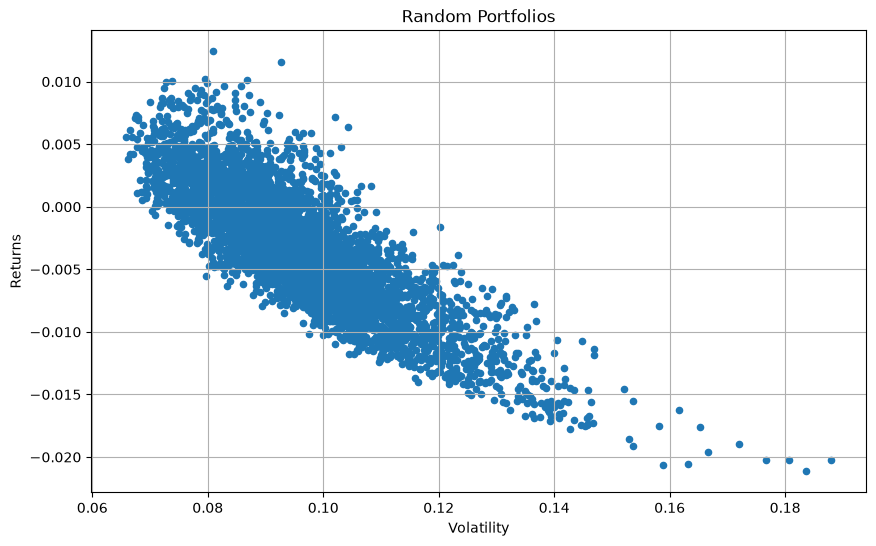

In [7]:
# 6. Plot the set of random porfolios
random_portfolios.plot.scatter(x='Volatility', y='Returns', figsize=(10, 6), grid=True)
plt.title('Random Portfolios')
plt.xlabel('Volatility')
plt.ylabel('Returns')
plt.savefig('charts/01_project_random_portfolios.png')
plt.show()

In [8]:
import cvxopt as opt
from cvxopt import blas, solvers
solvers.options['show_progress'] = False     # don't print the solver's working

def optimal_portfolio(returns):
    n = returns.shape[1]
    returns = np.transpose(returns.values)
    
    N = 100
    mus = [10**(5.0 * t/N - 1.0) for t in range(N)]
    
    # Convert to cvxopt matrices
    S = opt.matrix(np.cov(returns))
    pbar = opt.matrix(np.mean(returns, axis=1))
    
    # Create constraint matrices
    G = -opt.matrix(np.eye(n)) # negative n x n identity matrix
    h = opt.matrix(0.0, (n,1))
    A = opt.matrix(1.0, (1,n))
    b = opt.matrix(1.0)
    
    # Calculate efficient frontier weights using quadratic programming
    portfolios = [solvers.qp(mu*S, -pbar, G, h, A, b)['x'] for mu in mus]
    ## CALCULATE RISKS AND RETURNS FOR FRONTIER
    returns = [blas.dot(pbar, x) for x in portfolios]
    risks = [np.sqrt(blas.dot(x, S*x)) for x in portfolios]
    ## CALCULATE THE 2ND DEGREE POLYNOMIAL OF THE FRONTIER CURVE
    m1 = np.polyfit(returns, risks, 2)
    x1 = np.sqrt(m1[2] / m1[0])
    # CALCULATE THE OPTIMAL PORTFOLIO
    wt = solvers.qp(opt.matrix(x1 * S), -pbar, G, h, A, b)['x']
    return np.asarray(wt), returns, risks

In [9]:
# 7. Calculate the set of portfolios on the EF
weights, returns, risks = optimal_portfolio(returns_quarterly[1:])  

8. Plot the efficient frontier as a yellow line with dots on the plot.

   Use the following code to set the x-label, y-label, and title:
   
   ```py
   plt.ylabel('Expected Returns', fontsize=14)
   plt.xlabel('Volatility (Std. Deviation)', fontsize=14)
   plt.title('Efficient Frontier', fontsize=24)
   ```

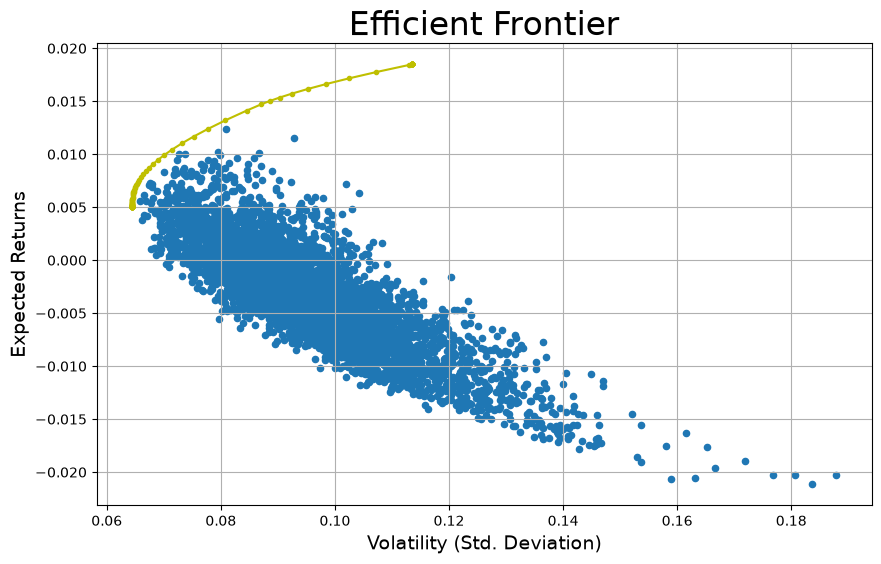

In [10]:
# 8. Plot the set of portfolios on the EF
random_portfolios.plot.scatter(x='Volatility', y='Returns', figsize=(10, 6), grid=True)
plt.plot(risks, returns, 'y-o', markersize=3)
plt.title('Efficient Frontier', fontsize=24)
plt.xlabel('Volatility (Std. Deviation)', fontsize=14)
plt.ylabel('Expected Returns', fontsize=14)
plt.show()

## How Do Two Additional Assets Affect the EF?

9. You inherited a portfolio with five assets, stored in **stock_data_weak.csv**:

   Asset | Expected Return
   --- | ---
   General Electric | -0.0120
   Chesapeake Energy | -0.0306
   AT&T | -0.0014
   Cisco Systems | 0.0184
   Campbell Soup | 0.0084

   View the output below, which visualizes the efficient frontier for these asstes.

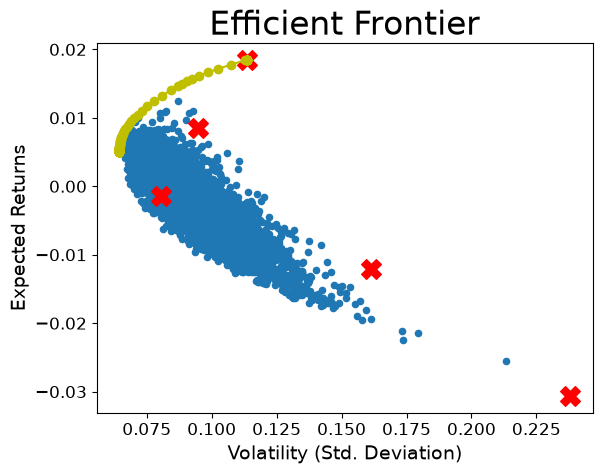

In [11]:
path = '../../data/stock_data_weak.csv'

# Load the stock data
stock_data = pd.read_csv(path)

# Find the quarterly for each period
selected = list(stock_data.columns[1:])
returns_quarterly = stock_data[selected].pct_change()

# Find the expected returns
expected_returns = returns_quarterly.mean()

# Find the covariance
cov_quarterly = returns_quarterly.cov()

# Find a set of random portfolios
random_portfolios = return_portfolios(expected_returns, cov_quarterly)

# Plot the set of random portfolios
random_portfolios.plot.scatter(x='Volatility', y='Returns', fontsize=12)

# Calculate the set of portfolios on the EF
weights, returns, risks = optimal_portfolio(returns_quarterly[1:])

# Plot the set of portfolios on the EF
plt.plot(risks, returns, 'y-o')
plt.ylabel('Expected Returns',fontsize=14)
plt.xlabel('Volatility (Std. Deviation)',fontsize=14)
plt.title('Efficient Frontier', fontsize=24)

# Compare the set of portfolios on the EF
single_asset_std=np.sqrt(np.diagonal(cov_quarterly))
plt.scatter(single_asset_std,expected_returns,marker='X',color='red',s=200)

plt.show()

10. You decide to diversify the portfolio with a couple of assets to increase the expected return of portfolios on the efficient frontier.

    You choose to add Bank of America and Marvel, so your assets are:
    
    Asset | Expected Return
    --- | ---
    General Electric | -0.0120
    Chesapeake Energy | -0.0306
    AT&T | -0.0014
    Cisco Systems | 0.0184
    Campbell Soup | 0.0084
    Bank of America | 0.0341
    Marvel | 0.0369
    
    Change the `path` variable to **stock_data2.csv** to visualize this new efficient frontier.

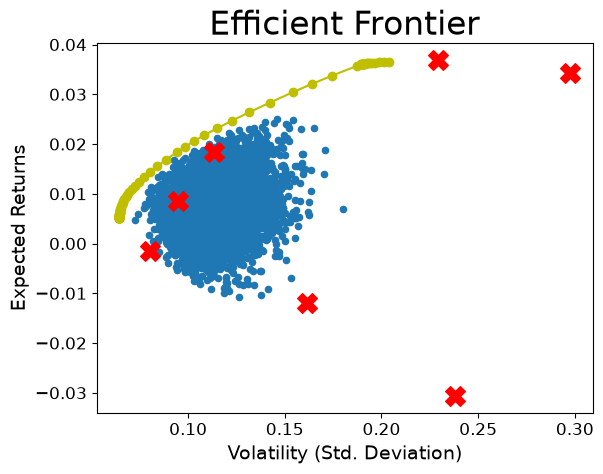

In [12]:
# 10. Change the path variable.
path = '../../data/stock_data2.csv'

# Load the stock data
stock_data = pd.read_csv(path)

# Find the quarterly for each period
selected = list(stock_data.columns[1:])
returns_quarterly = stock_data[selected].pct_change()

# Find the expected returns
expected_returns = returns_quarterly.mean()

# Find the covariance
cov_quarterly = returns_quarterly.cov()

# Find a set of random portfolios
random_portfolios = return_portfolios(expected_returns, cov_quarterly)

# Plot the set of random portfolios
random_portfolios.plot.scatter(x='Volatility', y='Returns', fontsize=12)

# Calculate the set of portfolios on the EF
weights, returns, risks = optimal_portfolio(returns_quarterly[1:])

# Plot the set of portfolios on the EF
plt.plot(risks, returns, 'y-o')
plt.ylabel('Expected Returns',fontsize=14)
plt.xlabel('Volatility (Std. Deviation)',fontsize=14)
plt.title('Efficient Frontier', fontsize=24)

# Compare the set of portfolios on the EF
single_asset_std=np.sqrt(np.diagonal(cov_quarterly))
plt.scatter(single_asset_std,expected_returns,marker='X',color='red',s=200)

plt.show()

11. It's hard to visualize how much the efficient frontier improved with these assets. Let's plot the original frontier on the same figure. Use the following code to do this:

    ```py
    weak_EF = pd.read_csv('../../data/weak_risks_returns.csv')
    plt.plot(weak_EF['Risks'], weak_EF['Returns'], 'g-o')
    ```
    
    To get a better view of the efficient frontier, you may want to comment out the following line:
    
    ```py
    random_portfolios.plot.scatter(x='Volatility', y='Returns', fontsize=12)
    ```
    
    By adding the two high-return assets, we increased the expected return of portfolios on the efficient frontier.

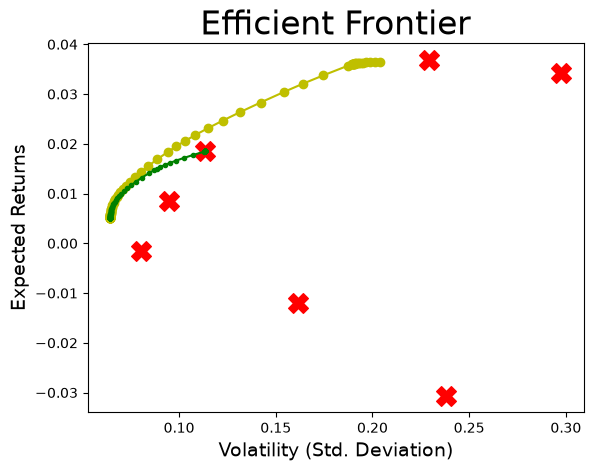

In [13]:
# 11. Compare to original
plt.plot(risks, returns, 'y-o')
plt.ylabel('Expected Returns',fontsize=14)
plt.xlabel('Volatility (Std. Deviation)',fontsize=14)
plt.title('Efficient Frontier', fontsize=24)

# Compare the set of portfolios on the EF
single_asset_std=np.sqrt(np.diagonal(cov_quarterly))
plt.scatter(single_asset_std,expected_returns,marker='X',color='red',s=200)


weak_EF = pd.read_csv('../../data/weak_risks_returns.csv')
plt.plot(weak_EF['Risks'], weak_EF['Returns'], 'g-o', markersize=3)
plt.show()

12. If you look at the expected returns of assets in your portfolio, you'll notice that General Electric and Chesapeake Energy have a large negative return (i.e. you expect to lose money).

    Asset | Expected Return
    --- | ---
    General Electric | -0.0120
    Chesapeake Energy | -0.0306
    AT&T | -0.0014
    Cisco Systems | 0.0184
    Campbell Soup | 0.0084
    Bank of America | 0.0341
    Marvel | 0.0369
    
    This begs the question: do we need these assets in our portfolio? Given their poor expected return, we should only keep them if they are uniquely uncorrelated to the rest of the assets in the portfolio.
    
    To check the effects of these assets, we calculated the efficient frontier for a portfolio **without** General Electric and Chesapeake Energy. Add the following code to the code block below to visualize this efficient frontier on the same plot.
    
    ```py
    strong_EF = pd.read_csv('../../data/strong_risks_returns.csv')
    plt.plot(strong_EF['Risks'], strong_EF['Returns'], 'k-x')
    ```
    
    What do you notice when you run the code?

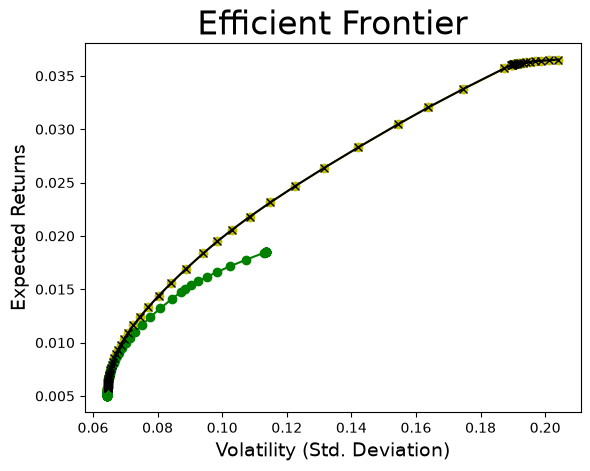

In [14]:
# 12. Plot Efficient Frontier Without Two Assets
plt.plot(risks, returns, 'y-o')
plt.ylabel('Expected Returns',fontsize=14)
plt.xlabel('Volatility (Std. Deviation)',fontsize=14)
plt.title('Efficient Frontier', fontsize=24)
weak_EF = pd.read_csv('../../data/weak_risks_returns.csv')
plt.plot(weak_EF['Risks'], weak_EF['Returns'], 'g-o')

strong_EF = pd.read_csv('../../data/strong_risks_returns.csv')
plt.plot(strong_EF['Risks'], strong_EF['Returns'], 'k-x')
plt.show()


**My reading of step 12:**

- **Green vs black:** weak has lower returns. Its frontier is shorter and lower, because it lacks the two high-return stocks, Bank of America and Marvel.
- **Yellow vs black:** almost identical. Removing GE and Chesapeake changes practically nothing.
- **Conclusion:** GE and Chesapeake don't earn their place. They have negative returns and aren't uncorrelated enough to make up for it (GE moves with AT&T at 0.55 and with Bank of America at 0.50; Chesapeake with Marvel at 0.61). The portfolio is just as good without them, and simpler.

## Finding the Best Efficient Frontier

13. Next, you will use your understanding of expected returns and covariances to inform portfolio decisions. We have asset data for 10 stocks, stored in **stock_data3.csv**.

    View the output from the code block below.
    
    You should see two efficient frontiers. We calculate the better efficient frontier (green dots) using all ten assets. We calculate the other efficient frontier using only five assets from the portfolio.
    
    Your job is to choose five assets from the following list to create the best efficient frontier.
    
    ```
    ['PFE', 'TGT', 'M', 'VZ', 'JPM', 'MRO', 'KO', 'PG', 'CVS', 'HPQ']
    ```
    
    Use the expected returns and covariance table, and set the `selected` variable equal to a list with five of these assets.

JPM    0.034781
M      0.021962
CVS    0.016124
PFE    0.015530
TGT    0.014783
VZ     0.004856
PG     0.004132
HPQ   -0.000237
KO    -0.002050
MRO   -0.008010
dtype: float64
          PFE       TGT         M        VZ       JPM       MRO        KO  \
PFE  0.010005  0.001738  0.005978  0.004071  0.007016  0.009721  0.002086   
TGT  0.001738  0.012874  0.015762  0.002188  0.007805  0.002239  0.002534   
M    0.005978  0.015762  0.038909  0.002804  0.016439  0.015110  0.005189   
VZ   0.004071  0.002188  0.002804  0.006958 -0.000407  0.005276  0.002586   
JPM  0.007016  0.007805  0.016439 -0.000407  0.023837  0.013848  0.002979   
MRO  0.009721  0.002239  0.015110  0.005276  0.013848  0.043166 -0.001516   
KO   0.002086  0.002534  0.005189  0.002586  0.002979 -0.001516  0.011021   
PG   0.004297  0.003148  0.005853  0.002094  0.006364  0.002834  0.001255   
CVS  0.004300  0.005384  0.012501  0.002052  0.005041  0.003689  0.003223   
HPQ  0.006996  0.007774  0.018937  0.003076  0.011523  

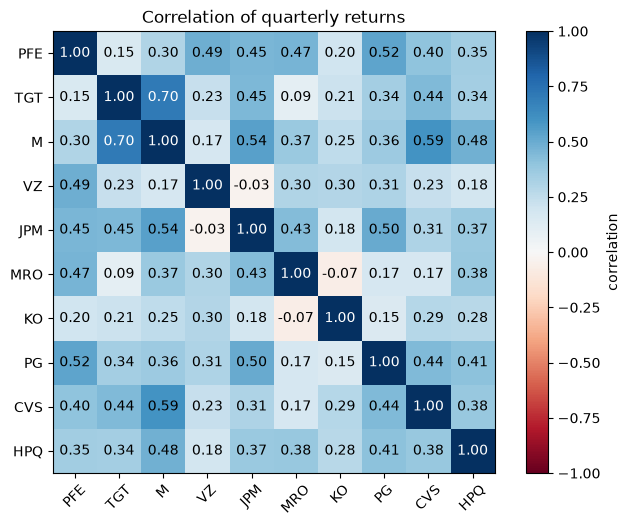

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

path='../../data/stock_data3.csv'

# 1. Load the stock data
stock_data = pd.read_csv(path)
selected = list(stock_data.columns[1:])
print(stock_data[selected].pct_change().mean().sort_values(ascending=False))
print(stock_data[selected].pct_change().cov())

returns_corr = stock_data[selected].pct_change().corr()  # correlation matrix of the returns

plt.figure(figsize=(8, 6.5))
plt.imshow(returns_corr, cmap='RdBu', vmin=-1, vmax=1)    
plt.colorbar(label='correlation')                         
plt.xticks(range(len(selected)), selected, rotation=45)   
plt.yticks(range(len(selected)), selected)                
for i in range(len(selected)):                            # i = row number 0 ... 9
    for j in range(len(selected)):                        # j = column number 0 ... 9 (loop inside a loop: 100 squares)
        value = returns_corr.iloc[i, j]                   # the number in row i, column j
        plt.text(j, i, f'{value:.2f}', ha='center', va='center',   # write it in the square: x = column j, y = row i,
                 color='white' if abs(value) > 0.6 else 'black')   # centred; white text on dark squares (one-line if)
plt.title('Correlation of quarterly returns')
plt.subplots_adjust(bottom=0.2)                           # room at the bottom for the tilted names
plt.show()

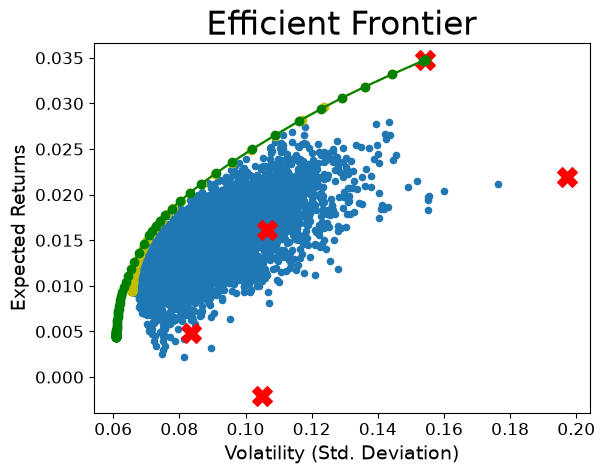

In [16]:

#stock_names = ['PFE', 'TGT', 'M', 'VZ', 'JPM', 'MRO', 'KO', 'PG', 'CVS', 'HPQ']
selected = ['JPM', 'M', 'VZ', 'CVS', 'KO']

# 2. Find the quarterly for each period
returns_quarterly = stock_data[selected].pct_change()


# 3. Find the expected returns 
expected_returns = returns_quarterly.mean()


# 4. Find the covariance 
cov_quarterly = returns_quarterly.cov()

# 5. Find a set of random portfolios
random_portfolios = return_portfolios(expected_returns, cov_quarterly) 

# 6. Plot the set of random portfolios
random_portfolios.plot.scatter(x='Volatility', y='Returns', fontsize=12)

# 7. Calculate the set of portfolios on the EF
weights, returns, risks = optimal_portfolio(returns_quarterly[1:])

# 8. Plot the set of portfolios on the EF
plt.plot(risks, returns, 'y-o')
plt.ylabel('Expected Returns',fontsize=14)
plt.xlabel('Volatility (Std. Deviation)',fontsize=14)
plt.title('Efficient Frontier', fontsize=24)

#pd.DataFrame({'Risks': risks, 'Returns': returns}).to_csv('../../data/all_ten.csv', index=False)

# 9. Compare the set of portfolios on the EF
single_asset_std=np.sqrt(np.diagonal(cov_quarterly))
plt.scatter(single_asset_std,expected_returns,marker='X',color='red',s=200)

# All 10
all_ten_EF = pd.read_csv('../../data/all_ten.csv')
plt.plot(all_ten_EF['Risks'], all_ten_EF['Returns'], 'g-o')
plt.show()


### My reasoning for step 13

**Goal:** choose 5 of the 10 stocks whose efficient frontier comes as close as possible to the all-ten frontier, at both ends: high return at the top, low risk on the left.

**1. Anchor: the highest return.** Sorted by expected return: JPM (3.5%), M, CVS, PFE, TGT, ... **JPM** is a must, because without it the frontier can't reach the top end.

**2. Candidates for return:** M, CVS, PFE and TGT, the next four. **M** moves only moderately with JPM (0.54), so I keep it.

**3. Remove twins:** M and TGT have a correlation of **0.70**. They're twins, so holding both adds little. M has the higher return, so **TGT goes**.

**4. First diversifier:** the stock that moves least with M is **VZ** (0.17). It also has one of the only two negative correlations, with JPM (-0.03), plus one of the lowest variances of all ten. So it diversifies against both high-return picks.

**5. One more for return: CVS or PFE?**

| | with M | with JPM | with VZ | average | return |
|---|---|---|---|---|---|
| CVS | 0.59 | 0.31 | 0.23 | **0.38** | **1.6%** |
| PFE | 0.30 | 0.45 | 0.49 | 0.41 | 1.55% |

**CVS** moves slightly less with my picks and earns slightly more.

**6. Second diversifier, from the other negative pair (MRO-KO):**

| | average correlation with JPM, M, VZ, CVS | own variance | return |
|---|---|---|---|
| **KO** | **0.25** | **0.011** | **-0.2%** |
| MRO | 0.32 | 0.043 | -0.8% |

**KO** wins on all three.

**My pick: JPM, M, VZ, CVS, KO.** The yellow frontier lies almost on top of the green all-ten one; only the lowest-risk end stops slightly earlier.

### Comparison with Codecademy's solution

Codecademy picked **JPM, VZ, M, CVS, TGT**: JPM (highest return) -> VZ (least correlated with JPM) -> the next three highest returns. That's four of my five; the difference is **TGT instead of KO**.

| | lowest possible risk | highest return | average extra risk vs all ten |
|---|---|---|---|
| all ten | 0.061 | 3.48% | - |
| **mine** | **0.066** | 3.48% | 0.0003 |
| Codecademy's | 0.068 | 3.48% | 0.0001 |

- **Top end:** identical, carried by JPM in both.
- **Left end:** mine reaches lower risk. KO does the job TGT can't, because TGT moves with M.
- **Middle:** Codecademy's is a hair closer, which is invisible on the chart.

Practically a tie. Codecademy's "next highest returns" rule is simpler, but it misses that M and TGT move together.